# B5: Apply K-Means or hierarchical clustering to sales_data_sample.csv; determine the number of clusters using the elbow method.

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('../ML/5-sales_data_sample.csv', encoding_errors='ignore')
df

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2818,10350,20,100.00,15,2244.40,12/2/2004 0:00,Shipped,4,12,2004,...,"C/ Moralzarzal, 86",NaN,Madrid,NaN,28034,Spain,EMEA,Freyre,Diego,Small
2819,10373,29,100.00,1,3978.51,1/31/2005 0:00,Shipped,1,1,2005,...,Torikatu 38,NaN,Oulu,NaN,90110,Finland,EMEA,Koskitalo,Pirkko,Medium
2820,10386,43,100.00,4,5417.57,3/1/2005 0:00,Resolved,1,3,2005,...,"C/ Moralzarzal, 86",NaN,Madrid,NaN,28034,Spain,EMEA,Freyre,Diego,Medium
2821,10397,34,62.24,1,2116.16,3/28/2005 0:00,Shipped,1,3,2005,...,1 rue Alsace-Lorraine,NaN,Toulouse,NaN,31000,France,EMEA,Roulet,Annette,Small


In [3]:
df.isnull().sum()

ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE               0
dtype: int64

In [4]:
df = df[['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'QTR_ID', 'MONTH_ID', 'YEAR_ID', 'DEALSIZE']]
df

,QUANTITYORDERED,PRICEEACH,SALES,QTR_ID,MONTH_ID,YEAR_ID,DEALSIZE
0,30,95.70,2871.00,1,2,2003,Small
1,34,81.35,2765.90,2,5,2003,Small
2,41,94.74,3884.34,3,7,2003,Medium
3,45,83.26,3746.70,3,8,2003,Medium
4,49,100.00,5205.27,4,10,2003,Medium
...,...,...,...,...,...,...,...
2818,20,100.00,2244.40,4,12,2004,Small
2819,29,100.00,3978.51,1,1,2005,Medium
2820,43,100.00,5417.57,1,3,2005,Medium
2821,34,62.24,2116.16,1,3,2005,Small


In [5]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['DEALSIZE'] = le.fit_transform(df['DEALSIZE'])
df

,QUANTITYORDERED,PRICEEACH,SALES,QTR_ID,MONTH_ID,YEAR_ID,DEALSIZE
0,30,95.70,2871.00,1,2,2003,2
1,34,81.35,2765.90,2,5,2003,2
2,41,94.74,3884.34,3,7,2003,1
3,45,83.26,3746.70,3,8,2003,1
4,49,100.00,5205.27,4,10,2003,1
...,...,...,...,...,...,...,...
2818,20,100.00,2244.40,4,12,2004,2
2819,29,100.00,3978.51,1,1,2005,1
2820,43,100.00,5417.57,1,3,2005,1
2821,34,62.24,2116.16,1,3,2005,2


In [6]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X = scaler.fit_transform(df)

In [7]:
from sklearn.cluster import KMeans
inertia = []
for i in range(1, 15):
    km = KMeans(n_clusters=i)
    km.fit(X)
    inertia.append(km.inertia_)

<Axes: >

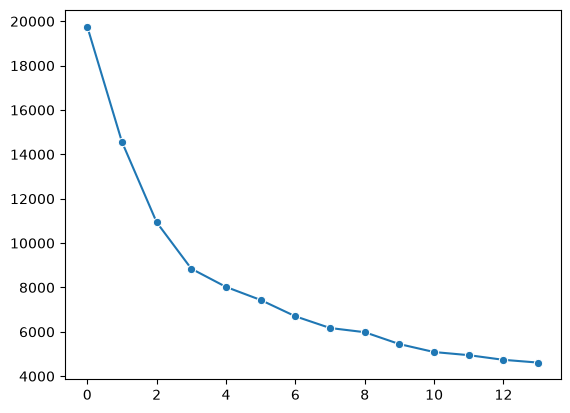

In [16]:
import seaborn as sns

sns.lineplot(data=inertia, marker='o')

In [17]:
kmm = KMeans(n_clusters=5)
kmm.fit_transform(X)
df['CLUSTER'] = kmm.predict(X)
df

,QUANTITYORDERED,PRICEEACH,SALES,QTR_ID,MONTH_ID,YEAR_ID,DEALSIZE,CLUSTER
0,30,95.70,2871.00,1,2,2003,2,2
1,34,81.35,2765.90,2,5,2003,2,2
2,41,94.74,3884.34,3,7,2003,1,1
3,45,83.26,3746.70,3,8,2003,1,1
4,49,100.00,5205.27,4,10,2003,1,1
...,...,...,...,...,...,...,...,...
2818,20,100.00,2244.40,4,12,2004,2,4
2819,29,100.00,3978.51,1,1,2005,1,3
2820,43,100.00,5417.57,1,3,2005,1,3
2821,34,62.24,2116.16,1,3,2005,2,2
